In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from slum_segmentation import helper_functions
from slum_segmentation import raw_dataset
from types import SimpleNamespace

# Trim `Makoko` city raster and mask 

(149, 269)


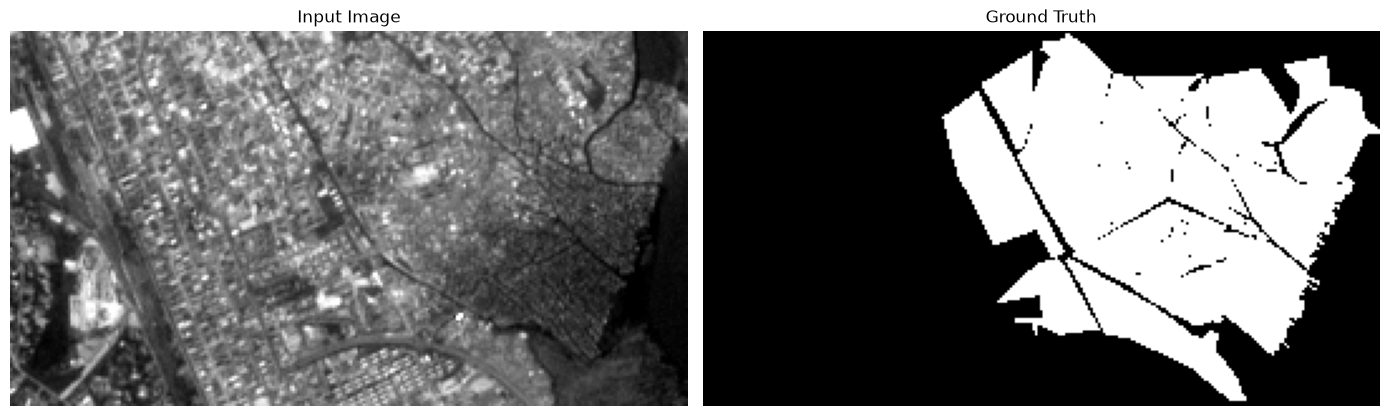

(146, 174)


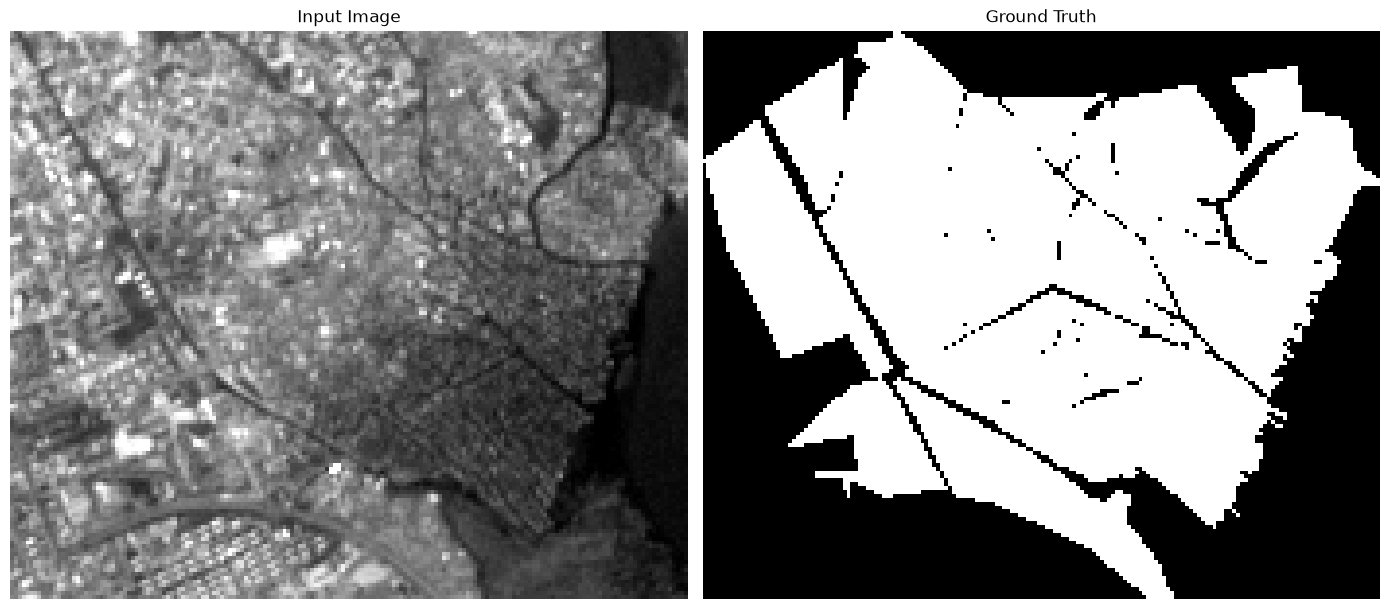

In [3]:
makoko_image_path = raw_dataset.cities.makoko.get_image_path()
makoko_image = helper_functions.convert_tif_to_np(makoko_image_path)

makoko_mask_path = raw_dataset.cities.makoko.get_mask_path()
makoko_mask = helper_functions.convert_tif_to_np(makoko_mask_path)[0]

print(makoko_mask.shape)
helper_functions.visualize_image_and_mask(makoko_image, makoko_mask)

start_x, start_y, width, height = helper_functions.get_bbox(makoko_mask)

makoko_image_cropped = makoko_image[:, start_y:start_y + height, start_x:start_x + width]
makoko_mask_cropped = makoko_mask[start_y:start_y + height, start_x:start_x + width]

print(makoko_mask_cropped.shape)
helper_functions.visualize_image_and_mask(makoko_image_cropped, makoko_mask_cropped)

# Trim `Lower` city raster and mask 

(46, 567)


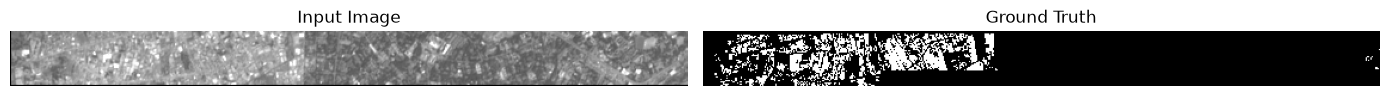

(10, 44, 237)


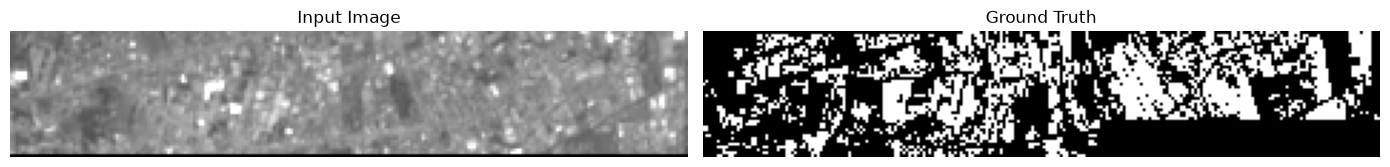

In [4]:
lower_image_path = raw_dataset.cities.lower.get_image_path()
lower_image = helper_functions.convert_tif_to_np(lower_image_path)

lower_mask_path = raw_dataset.cities.lower.get_mask_path()
lower_mask = helper_functions.convert_tif_to_np(lower_mask_path)[0]

print(lower_mask.shape)
helper_functions.visualize_image_and_mask(lower_image, lower_mask)

# visually we can see that the main slum region only occupies the left half of the image, 
# so we can safely use 60% as the cutoff point
lower_mask_cut_off = helper_functions.remove_truth_area(lower_mask, 0.6)
start_x, start_y, width, height = helper_functions.get_bbox(lower_mask_cut_off)

lower_image_cropped = lower_image[:, start_y:start_y + height, start_x:start_x + width]
lower_mask_cropped = lower_mask[start_y:start_y + height, start_x:start_x + width]

print(lower_image_cropped.shape)
helper_functions.visualize_image_and_mask(lower_image_cropped, lower_mask_cropped)

# Accumulate all numpy images and masks (`capetown` will not be added)

In [5]:
city_image_mask_pairs = {}

for city in vars(raw_dataset.cities).values():
    if (city.name == raw_dataset.cities.capetown.name): continue
    if (city.name == raw_dataset.cities.makoko.name):
        city_image_mask_pairs[city.name] = (makoko_image_cropped, makoko_mask_cropped)
    if (city.name == raw_dataset.cities.lower.name):
        city_image_mask_pairs[city.name] = (lower_image_cropped, lower_mask_cropped)
    else:
        image_path = city.get_image_path()
        image = helper_functions.convert_tif_to_np(image_path)

        mask_path = city.get_mask_path()
        mask = helper_functions.convert_tif_to_np(mask_path)[0]

        city_image_mask_pairs[city.name] = (image, mask)

# Apply correction to datatypes and fix invalid values in the masks

In [6]:
for city_name, city_image_mask_pair in city_image_mask_pairs.items():
    image, mask = city_image_mask_pair

    normalized_image = image.astype(np.float32)
    corrected_mask = np.clip(mask, 0, 1).astype(np.uint8)

    city_image_mask_pairs[city_name] = (normalized_image, corrected_mask)

In [7]:
for city_name, city_image_mask_pair in city_image_mask_pairs.items():
    image, mask = city_image_mask_pair
    np.save(f"../data/preprocessed/{city_name}/image.npy", image)
    np.save(f"../data/preprocessed/{city_name}/mask.npy", mask)

# Verify changes

In [8]:
from slum_segmentation import np_dataset

for city_name, city in vars(np_dataset.cities).items():
    image = city.get_image()
    mask = city.get_mask()

    assert(image.shape[0] == 10)
    assert(image.shape[1] == mask.shape[0])
    assert(image.shape[2] == mask.shape[1])
    assert(image.dtype == np.float32)
    assert(mask.dtype == np.uint8)